# 02 Regression models: predicting weekly household expenditure

**Goal of this notebook:** predict weekly household expenditure (a number in GBP) with three regression models and compare them fairly.

- **Models:** linear regression, random forest, XGBoost.
- **Two predictor settings:** Setting A (the four ANOVA variables from the practicum) and Setting B (all usable variables, including income).
- **Baseline:** the practicum's R² = 0.412, re-scored on the same split as every other model.
- **Measures:** R², RMSE and MAE (see Chapter 3.4 of the thesis).

How to use it: run one cell at a time (Shift+Enter) and read the output. Every section ends with a **Check yourself** question.

## Step 1. Import the tools
Each line says what the tool is used for.

In [1]:
import sys
sys.path.append("..")            # lets us import our own code from the src/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer          # applies different steps to different columns
from sklearn.pipeline import Pipeline                  # chains preprocessing + model into one object
from sklearn.preprocessing import OneHotEncoder        # turns category codes into 0/1 columns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.base import clone                         # makes an unfitted copy of a model

from src.data import load_clean, make_split
from src.config import (TARGET, FEATURES_A, FEATURES_B, NUMERIC, CATEGORICAL,
                        SEED, CV_FOLDS, FIG_DIR)

## Step 2. Load the cleaned data and make ONE shared split
Every model in the thesis uses the **same** 80/20 split (seed 42), so differences in the scores come from the models and not from a lucky split.
The test set is kept untouched until the final scoring.

In [2]:
df = load_clean()
train, test, cuts = make_split(df)

print("all rows:", len(df))
print("train rows:", len(train), "| test rows:", len(test))

all rows: 5144
train rows: 4115 | test rows: 1029


**Check yourself:** why do we split the data before fitting anything? (Hint: what would happen if the test households were used to choose the model settings?)

**Answer:** We split the data so the model is trained on one group of households and evaluated on different households it has not seen. If we used the test households to choose the model or its settings, information from the test set would influence our choices and make the final score less trustworthy. Keeping the test set separate gives a fairer estimate of how the model may perform on new households.

## Step 3. Two small helpers
1. `make_preprocessor` turns each category column into 0/1 columns (one-hot encoding). Income is a number, so it is passed through unchanged.
2. `get_scores` calculates the three measures for a set of predictions.

In [3]:
def make_preprocessor(features):
    cat_cols = [c for c in features if c in CATEGORICAL]
    num_cols = [c for c in features if c in NUMERIC]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", num_cols),
    ])


def get_scores(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),   # same unit as the target: GBP per week
        "MAE": mean_absolute_error(y_true, y_pred),        # average absolute error in GBP per week
    }

**Check yourself:** RMSE and MAE are both in GBP per week. Which one punishes a very large error more, and why?

**Answer:** RMSE penalises a very large error more than MAE because it squares each error before averaging. For example, an error of £200 has a much bigger effect on RMSE than an error of £100. MAE is the average absolute error in pounds per week, so it is usually easier to interpret directly.

## Step 4. The baseline: the practicum's four-variable model
First we check that we can reproduce the practicum's R² = 0.412 on all 5,144 households.
Then we do the fair version: fit on the training set only and score on the test set.

In [4]:
# 4a. Reproduction on the full sample (this is how the practicum got its number)
baseline = Pipeline([("prep", make_preprocessor(FEATURES_A)), ("model", LinearRegression())])
baseline.fit(df[FEATURES_A], df[TARGET])
full_r2 = r2_score(df[TARGET], baseline.predict(df[FEATURES_A]))
print("Full-sample R2 (practicum-style):", round(full_r2, 4))

Full-sample R2 (practicum-style): 0.4124


In [5]:
# 4b. Fair version: fit on train, score on the unseen test set
baseline_fair = Pipeline([("prep", make_preprocessor(FEATURES_A)), ("model", LinearRegression())])
baseline_fair.fit(train[FEATURES_A], train[TARGET])
base_scores = get_scores(test[TARGET], baseline_fair.predict(test[FEATURES_A]))
print({k: round(v, 3) for k, v in base_scores.items()})

{'R2': 0.416, 'RMSE': 222.136, 'MAE': 170.814}


**Check yourself:** why is the test-set R² a more honest number than the full-sample R²? Is it much lower here?

**Answer:** Test-set R² is more honest for estimating performance on new households because the model was not fitted using those households. Here, the full-sample R² is **0.4124**, while the held-out test R² is **0.416**. The test score is slightly higher rather than lower; this can happen because the test sample may be a little easier to predict. The two values are very close, so the result is broadly consistent.

## Step 5. One function to run a model
For each model and predictor setting we do the same four things:
1. Build a pipeline (preprocessing + model).
2. If the model has settings to tune, try a small grid of values with 5-fold cross-validation **on the training set only**, and keep the best.
3. Report the cross-validated R² (from the training set).
4. Score the best model once on the test set.

Linear regression has no settings to tune, so it skips step 2.

In [6]:
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
results = []        # one row per (setting, model)
best_models = {}    # keep the fitted models so we can reuse them later


def run_model(setting, features, model_name, model, grid):
    pipe = Pipeline([("prep", make_preprocessor(features)), ("model", model)])
    X_train, y_train = train[features], train[TARGET]

    if grid:   # tune the settings with cross-validation on the training set only
        search = GridSearchCV(pipe, grid, cv=cv, scoring="r2", n_jobs=-1)
        search.fit(X_train, y_train)
        best, cv_r2, params = search.best_estimator_, search.best_score_, search.best_params_
    else:      # nothing to tune
        best = pipe.fit(X_train, y_train)
        cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2").mean()
        params = {}

    scores = get_scores(test[TARGET], best.predict(test[features]))
    results.append({"Setting": setting, "Model": model_name, "CV R2 (train)": cv_r2,
                    "Test R2": scores["R2"], "Test RMSE": scores["RMSE"], "Test MAE": scores["MAE"],
                    "Best settings": str(params)})
    best_models[(setting, model_name)] = best

**Check yourself:** why is the grid search run on the training set and not on the whole data set?

**Answer:** Grid search compares model settings, so it must use only the training data. If it used the test set, the settings would be indirectly selected based on the test results, making the final score less independent. The notebook uses five-fold cross-validation within the training data to tune models, then evaluates the selected models on the held-out test set.

## Step 6. The three models
The grids are small on purpose: they are quick to run and easy to explain.

In [7]:
models = {
    "Linear regression": (LinearRegression(), {}),
    "Random forest": (
        RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
        {"model__max_depth": [5, 10], "model__min_samples_leaf": [5, 10]},
    ),
    "XGBoost": (
        XGBRegressor(random_state=SEED, n_jobs=-1),
        {"model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.1], "model__n_estimators": [200, 400]},
    ),
}

### Setting A: the four ANOVA variables
Occupational class, tenure, number of adults, number of children.

In [8]:
for name, (model, grid) in models.items():
    run_model("A", FEATURES_A, name, clone(model), grid)
pd.DataFrame(results).round(3)

,Setting,Model,CV R2 (train),Test R2,Test RMSE,Test MAE,Best settings
0,A,Linear regression,0.407,0.416,222.136,170.814,{}
1,A,Random forest,0.403,0.412,222.756,172.166,"{'model__max_depth': 5, 'model__min_samples_le..."
2,A,XGBoost,0.411,0.415,222.252,170.665,"{'model__learning_rate': 0.03, 'model__max_dep..."


### Setting B: all usable variables, including income

In [9]:
for name, (model, grid) in models.items():
    run_model("B", FEATURES_B, name, clone(model), grid)

## Step 7. Results table
The baseline from Step 4 is added so everything is in one place.

In [10]:
results_df = pd.DataFrame(results)
baseline_row = {"Setting": "A", "Model": "ANOVA baseline (linear, 4 variables)", "CV R2 (train)": np.nan,
                "Test R2": base_scores["R2"], "Test RMSE": base_scores["RMSE"], "Test MAE": base_scores["MAE"],
                "Best settings": "-"}
final_table = pd.concat([pd.DataFrame([baseline_row]), results_df], ignore_index=True)
final_table.round(3).to_csv("../reports/regression_results.csv", index=False)
final_table.round(3)

,Setting,Model,CV R2 (train),Test R2,Test RMSE,Test MAE,Best settings
0,A,"ANOVA baseline (linear, 4 variables)",NaN,0.416,222.136,170.814,-
1,A,Linear regression,0.407,0.416,222.136,170.814,{}
2,A,Random forest,0.403,0.412,222.756,172.166,"{'model__max_depth': 5, 'model__min_samples_le..."
3,A,XGBoost,0.411,0.415,222.252,170.665,"{'model__learning_rate': 0.03, 'model__max_dep..."
4,B,Linear regression,0.540,0.554,194.058,145.059,{}
5,B,Random forest,0.534,0.559,192.935,143.288,"{'model__max_depth': 5, 'model__min_samples_le..."
6,B,XGBoost,0.544,0.568,191.035,142.326,"{'model__learning_rate': 0.03, 'model__max_dep..."


**Check yourself:** (1) In Setting A, is any model clearly better than the baseline? (2) How much does R² change when income and the other variables are added (Setting B)? (3) Do the cross-validated R² and the test R² agree?

**Answer:**

1. **Setting A:** No model clearly beats the practicum baseline. The baseline and linear regression both have test R² = **0.416**. Random forest is slightly lower at **0.412**, and XGBoost is **0.415**. These differences are very small.
2. **Setting B:** Test R² improves substantially when income and the other usable variables are added. Linear regression rises from **0.416 to 0.554** (+0.138), random forest from **0.412 to 0.559** (+0.147), and XGBoost from **0.415 to 0.568** (+0.153). XGBoost's RMSE also falls from about **£222 to £191 per week**.
3. **Cross-validation versus test results:** They agree on the overall pattern: Setting B performs better than Setting A, and XGBoost is strongest overall in Setting B. The exact rankings are not identical in every case; for example, linear regression has a slightly higher test R² than XGBoost in Setting A. This is not necessarily a problem because cross-validation and test scores are calculated on different data subsets.

## Step 8. A picture of the results
Test R² for each model and each setting. The dashed line is the practicum's baseline on the same test set.

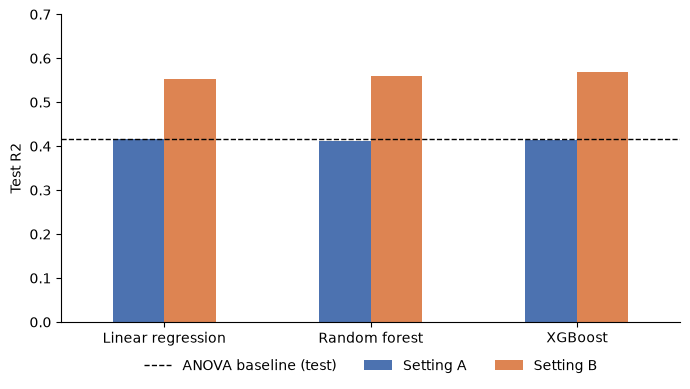

In [11]:
plot_df = results_df.pivot(index="Model", columns="Setting", values="Test R2")
plot_df = plot_df.loc[["Linear regression", "Random forest", "XGBoost"]]
plot_df.columns = ["Setting " + c for c in plot_df.columns]

ax = plot_df.plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452"], rot=0)
ax.axhline(base_scores["R2"], color="black", linestyle="--", linewidth=1, label="ANOVA baseline (test)")
ax.set_ylabel("Test R2")
ax.set_xlabel("")
ax.set_ylim(0, 0.7)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "regression_test_r2.pdf")
plt.savefig(FIG_DIR / "regression_test_r2.png", dpi=300)
plt.show()

## Step 9. Sensitivity check: survey weights
The main results above are **unweighted** (every household counts the same). As a check we refit each best model with the survey weight `weightar` and score it with weights too.
If the weighted scores tell the same story, the conclusions do not depend on the weighting choice.

In [12]:
w_train, w_test = train["weightar"], test["weightar"]
rows = []

for (setting, model_name), best in best_models.items():
    features = FEATURES_A if setting == "A" else FEATURES_B

    # same model and settings, refitted WITH weights
    weighted = clone(best)
    weighted.fit(train[features], train[TARGET], model__sample_weight=w_train)

    r2_unweighted_fit = r2_score(test[TARGET], best.predict(test[features]), sample_weight=w_test)
    r2_weighted_fit = r2_score(test[TARGET], weighted.predict(test[features]), sample_weight=w_test)
    rows.append({"Setting": setting, "Model": model_name,
                 "Weighted test R2 (unweighted fit)": r2_unweighted_fit,
                 "Weighted test R2 (weighted fit)": r2_weighted_fit})

sens = pd.DataFrame(rows)
sens.round(3).to_csv("../reports/regression_weighted_check.csv", index=False)
sens.round(3)

,Setting,Model,Weighted test R2 (unweighted fit),Weighted test R2 (weighted fit)
0,A,Linear regression,0.428,0.428
1,A,Random forest,0.424,0.421
2,A,XGBoost,0.428,0.427
3,B,Linear regression,0.556,0.556
4,B,Random forest,0.557,0.556
5,B,XGBoost,0.568,0.569


**Check yourself:** does the ranking of the models change when the weights are used?

**Answer:** The main conclusion does not change: **Setting B performs much better than Setting A, and XGBoost is the strongest model in Setting B.** With weighted scoring, Setting A's linear regression and XGBoost are almost tied (R² = **0.428** for the unweighted fits), while the weighted-fit results give linear regression **0.428** and XGBoost **0.427**. In Setting B, XGBoost remains best at **0.569**, just above random forest (**0.557**) and linear regression (**0.556**). These small differences suggest that using the survey weights does not materially change the overall interpretation. The weighted analysis is a sensitivity check, not proof that one weighting approach is always correct.

## Step 10. Summary

Write 4 to 6 sentences in your own words:

1. Does any model beat the practicum baseline in Setting A?
2. How much does Setting B improve on Setting A?
3. Which model is best, and is the difference large or small?
4. What does the weighted check say?

### Completed summary

The results show that no model clearly outperforms the practicum baseline when only the four original household characteristics are used. Adding income and the other usable variables improves test R² considerably, from around **0.41** in Setting A to **0.55–0.57** in Setting B. **XGBoost is the best overall model in Setting B**, with test R² = **0.568**, RMSE ≈ **£191 per week**, and MAE ≈ **£142 per week**. However, its advantage over random forest and linear regression is modest. The survey-weight sensitivity check produces a very similar pattern, so the main conclusion remains that the additional household variables improve expenditure prediction more than switching to a more complex model with only the original four predictors.